### **การเขียนโปรแกรมด้วย Libraly NumPy สำหรับการจัดการข้อมูลเสียง**

---

**N1 (โค้ด) ตัดช่วงสัญญาณด้วย slicing**
  - **สร้างอะไร:** `sr = 22050`, สัญญาณ sine 440 Hz แอมพลิจูด 1 ยาว 1 วินาที (ใช้ `create_sin` ของเมื่อวานได้) แล้วเขียนฟังก์ชัน `get_segment(x, sr, start_s, end_s)` ที่คืนเฉพาะช่วงเวลาที่ขอ (ใบ้: แปลงวินาทีเป็น index แล้วต้องเป็น `int`)
  - **ทดสอบ:** ขอช่วง 0.50–0.52 s แล้ว print `.shape` และ `.dtype` ของผลลัพธ์ จากนั้นพล็อตช่วงนี้โดยแกน x เป็นมิลลิวินาทีที่ **เริ่มที่ 500 ms** ไม่ใช่ 0
  - **ทดลองเพิ่ม:** แก้ค่าในช่วงที่ตัดมา (เช่น `seg[:] = 0`) แล้วเช็คว่าสัญญาณต้นฉบับเปลี่ยนไหม
  - **ตอบ 2 ข้อ:** (1) ช่วง 20 ms ได้กี่ sample และคำนวณด้วยมือตรงกับ `.shape` ไหม (2) ต้นฉบับเปลี่ยนหรือไม่ เพราะอะไร (ค้นคำว่า NumPy view vs copy) และถ้าไม่อยากให้เปลี่ยนต้องใช้อะไร
  - **เสร็จเมื่อ:** shape ตรงกับที่คำนวณ, กราฟแกน x เริ่มที่ 500 ms และตอบครบ 2 ข้อ

---

**ตอบ**: 
1. จากการคำนวณ $n_{T_{sr}} = T_{sr} \times S_r$ \
เมื่อ $n_{T_{sr}}$ คือ จำนวน Sampling ในช่วงเวลาที่ต้องการ, $T_{sr}$ คือ ช่วงเวลาที่ต้องการ และ $S_r$ คือ อัตราการ Sampling\
จะได้ว่า $T_{sr} = 20 \times 10^{-3} s, S_r = 22050$ \
ดังนั้น $n_{T_{sr}} = 20 \times 10^{-3} \times 22050 = 441$ และตรงกับ `.shape` ซึ่งเท่ากับ 441

2. NumPy as view copy จะมีฟังก์ชัน 2 แบบคือ arr.view() และ arr.copy() ความแตกต่างระหว่าง view และ copy คือ view จะชี้ไปยัง array ต้นฉบับมาและเมื่อมีการแก้ไขจะกระทบกับ array หลัก ในขณะที่ copy เมื่อมีการแก้ไขจะไม่กระทบกับ array หลัก ถ้าต้องการไม่ให้เปลี่ยนให้ใช้ `array.copy()` พบว่าสัญญาณต้นฉบับมีการเปลี่ยนแปลง เพราะว่า slicing ของ NumPy `x[a:b]` จะ Return ออกมาเป็น view ถ้าต้องการให้สัญญาณต้นไม่มีการเปลี่ยนแปลงให้ใช้ `x[a:b].copy()`

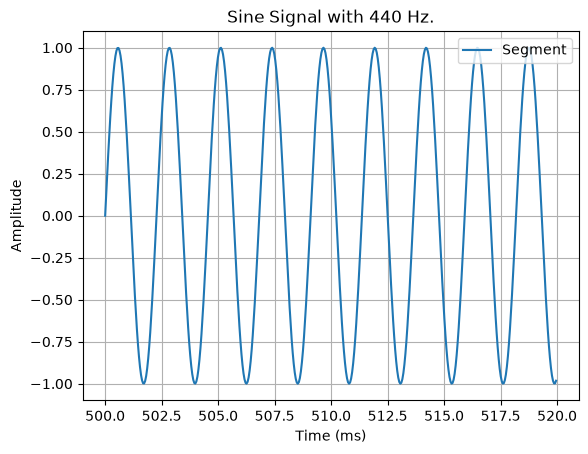

This is .shape of signal : (441,)
This is .dtype of signal : float64


In [1]:
# เขียนโปรแกรมสำหรับการสร้างสัญญาณ Sine ที่มีความถี่เท่ากับ 440 Hz, แอมพลิจูดเท่ากับ 1, ระยะเวลา 1 วินาที
import numpy as np
import matplotlib.pyplot as plt

frequency = 440 # Frequency ความถี่
amplitude = 1   # Amplitude แอมพลิจูด
sr = 22050      # Sampling Rate 
start_s = 0.5
end_s = 0.52

t = np.arange(0, 1, 1/sr)

# ฟังก์ชันสำหรับสร้างสัญญาณ Sine
def create_sin(A, f, t, phase=0):
    signal = A * np.sin((2 * np.pi * f * t) + phase)
    return signal

# ฟังก์ชันสำหรับการเลือกช่วงมาพล็อตกราฟ
def get_segment(signal, sr, start_s, end_s):
    n_start = int(sr * start_s) # สร้างตัวแปร index ของ Sample ที่เป็นตัวแรกของสัญญาณ
    n_end = int(sr * end_s)     # สร้างตัวแปร index ของ Sample ที่เป็นตัวสุดท้ายของสัญญาณ

    # ทำการ Return ค่าหลายค่าออกมาเป็น Tuples
    return signal[n_start:n_end], n_start, n_end

sine_signal = create_sin(amplitude, frequency, t)   # สร้างสัญญาณ Sine
# ทำการเลือกช่วงสัญญาณที่ต้องการผ่านฟังก์ชัน get_segment จะได้เป็น Index เริ่มต้นและสุดท้ายของสัญญาณ
segment_signal, n_start, n_end = get_segment(sine_signal, sr, start_s, end_s)


fig, ax = plt.subplots()
ax.grid()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine Signal with 440 Hz.")
ax.plot(t[n_start:n_end]*1000, segment_signal, label="Segment")
ax.legend(loc="upper right")
plt.show()

# ทำการแสดงผลลัพธ์ของ Signal
print(f'This is .shape of signal : {segment_signal.shape}')
print(f'This is .dtype of signal : {segment_signal.dtype}')

In [2]:
# ทำการทดลองเกี่ยวกับ NumPy as view copy

# .copy()
print(f"This is original signal : {sine_signal[11025:11030]}")
segment_signal = sine_signal[11025:11030].copy()
segment_signal[:] = 0 
print(f"This is original signal after .copy() : {sine_signal[11025:11030]}")

This is original signal : [3.13806691e-14 1.25050524e-01 2.48137848e-01 3.67329594e-01
 4.80754541e-01]
This is original signal after .copy() : [3.13806691e-14 1.25050524e-01 2.48137848e-01 3.67329594e-01
 4.80754541e-01]


In [3]:
print(f"This is original signal : {sine_signal[11025:11030]}")
segment_signal = sine_signal[11025:11030]    # ชี้ไปยัง Array sine_signal 
segment_signal[:] = 0   # กำหนดค่าทุกค่าใน Array เท่ากับ 0
print(f"This is original signal after segment_signal[:] = 0 : {sine_signal[11025:11030]}")

This is original signal : [3.13806691e-14 1.25050524e-01 2.48137848e-01 3.67329594e-01
 4.80754541e-01]
This is original signal after segment_signal[:] = 0 : [0. 0. 0. 0. 0.]


**N2 (โค้ด + ทฤษฎี) `==` กับ `np.allclose`**
  - **สร้างอะไร:** `x = 2*np.pi*440*t` จาก N1 แล้วสร้าง `a = np.sin(x + np.pi/2)` กับ `b = np.cos(x)`
  - **เทียบคู่ที่ 1:** `a` กับ `b` → print ผลของ `np.all(a == b)`, `np.allclose(a, b)` และ `np.max(np.abs(a - b))`
  - **เทียบคู่ที่ 2:** sine 440 Hz ช่วง sample `[0:100]` กับช่วงที่เลื่อนไป **1 วินาทีพอดี** `[22050:22150]` (ต้องสร้างสัญญาณยาวกว่า 1 วินาทีก่อน)
  - **เทียบคู่ที่ 3:** ช่วง `[0:100]` กับช่วงที่เลื่อนไป **50 sample** `[50:150]` (ประมาณ 1 คาบ)
  - **ตอบ 3 ข้อ:** (1) ทำไมคู่ที่ 1 ใช้ `==` แล้วได้ False ทั้งที่ทางคณิตศาสตร์เท่ากัน (2) คาบของ 440 Hz ยาวกี่ sample (ทศนิยม 2 ตำแหน่ง) (3) ใช้ข้อ (2) อธิบายว่าทำไมคู่ที่ 2 เป็น True แต่คู่ที่ 3 เป็น False
  - **เสร็จเมื่อ:** print ผลครบทั้ง 3 คู่ (คู่ละ `allclose` + max abs diff) และตอบครบ 3 ข้อ

  ___

  **ตอบ** : 
  1. เพราะคอมพิวเตอร์เก็บข้อมูลแบบเลขฐาน 2 และคอมพิวเตอร์ไม่สามารถเก็บตัวเลขแบบทศนิยมได้ละเอียดเหมือนทางคณิตศาสตร์และค่า $\frac{\pi}{2}$ ในทางคอมพิวเตอร์ก็ไม่สามารถเก็บได้ตรงเป๊ะ การใช้คำสั่ง `==` คือการเปรียบเทียบว่าค่าของ Operand 2 ตัวเท่ากันหรือไม่ ถ้าเท่ากันก็ Return เป็น True ถ้าไม่ก็ Return เป็น False และคำสั่ง np.all() เป็นการเปรียบเทียบกันทุกจุด ถ้ามีจุดใดจุดหนึ่ง Return เป็น False np.all() ก็จะ Return เป็น False ทันที ซึ่งในคำสั่งการตรวจสอบ Diff มี Diff เล็กน้อย ซึ่งโปรแกรมก็จะถือว่าไม่เท่ากันเลยมีการ Return เป็น False ออกมา
 

  2. คาบของสัญญาณ 440 Hz ยาวกี่ Sample สามารถคำนวณหาได้จาก \
  คาบของสัญญานสามารถคำนวณได้จาก $\frac{1}{440} \approx 2.273 \times 10^{-3} s$ \
  $S_r = 22050$
  1 คาบสัญญาณของสัญญาณ Sine 440 Hz มีจำนวน Sample เท่ากับ 50.11 samples

  3. คลื่นจะวนกลับมาซ้ำที่เดิมก็ต่อเมื่อเป็นจำนวนเต็มของคาบเท่านั้น แต่คาบของ 440 Hz ยาว 50.11 sample ซึ่งไม่ใช่จำนวนเต็ม จึงเลื่อนด้วยจำนวน Sample ที่เป็นจำนวนเต็มให้ครบ 1 รอบพอดีไม่ได้ ต้องเลื่อนไปไกลถึง 22050 Sample โดยในคู่ที่ 2 มีการเลื่อน Sample ไป 22050 Samples พอดี (= 440 รอบพอดี) และค่า Diff มีค่าเท่ากับ $4.7 \times 10^{-13}$ ซึ่งเข้าเงื่อนไขให้ np.allclose(a,b) return เป็น True ในขณะที่คู่ที่ 3 มีการเลื่อน Sample ไป 50 Samples (= 0.9977 รอบไม่ครบ 1 รอบ) และค่า Diff มีค่าเท่ากับ 0.0142 ซึ่งเข้าเงื่อนไขให้ np.allclose(a,b) return เป็น False

In [4]:
# คำนวณหาคาบของสัญญาณ Sine 440 Hz
period = 1/440
print(f'Period : {period:.3e}')

sample_1_period = sr * period
print(f'1 Period of Signal has {round(sample_1_period,2)} samples')

Period : 2.273e-03
1 Period of Signal has 50.11 samples


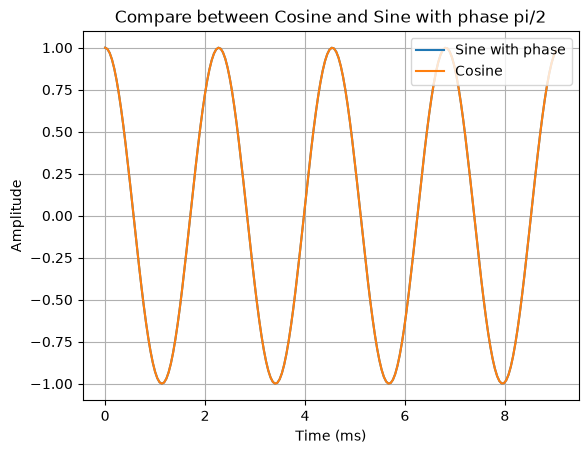

Compare between Cosine and Sine with phase pi/2
-----------------------------------------------
Results of np.all(a==b) : False
Results of np.allclose(a, b) : True
Rsults of np.max(np.abs(a - b)) : 1.6513992864147786e-13


In [5]:
# สร้างสัญญาณ Sine และ Cosine 
x = 2  *np.pi * frequency * t

a = np.sin(x + (np.pi/2))   # สร้างสัญญาณ Sine ที่มีมุมเฟสเท่ากับ pi/2 
b = np.cos(x)               # สร้างสัญญาณ Cosine

# -- Plot Graph --
fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Compare between Cosine and Sine with phase pi/2")
ax.grid()

# ต้องการให้แสดงคลื่นทั้งหมด 4 ลูก 1 ลูกเท่ากับ 1/440 อัตรา Sampling เท่ากับ 22050 ดังนั้น 4 * (1/440) * 22050 = 200
ax.plot(t[0:200]*1000, a[0:200], label="Sine with phase") 
ax.plot(t[0:200]*1000, b[0:200], label="Cosine")
ax.legend(loc="upper right")

plt.show()

# เปรียบเทียบคู่ที่ 1 a และ b
print("Compare between Cosine and Sine with phase pi/2")
print("-----------------------------------------------")
print(f'Results of np.all(a==b) : {np.all(a == b)}')    # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัว ถ้ามีตัวใดตัวหนึ่ง False ก็จะ False เลย
print(f'Results of np.allclose(a, b) : {np.allclose(a,b)}') # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัวเหมือนกัน แต่ว่าขอแค่ใกล้เคียงมากพอประมาณ atol + rtol × |b| 
print(f'Rsults of np.max(np.abs(a - b)) : {np.max(np.abs(a - b))}') # เปรียบเทียบจุดแต่ละจุดของกราฟนำมาลบกันและผ่านค่าสัมบูรณ์แล้วเลือกจุดที่แตกต่างกันมากที่สุด


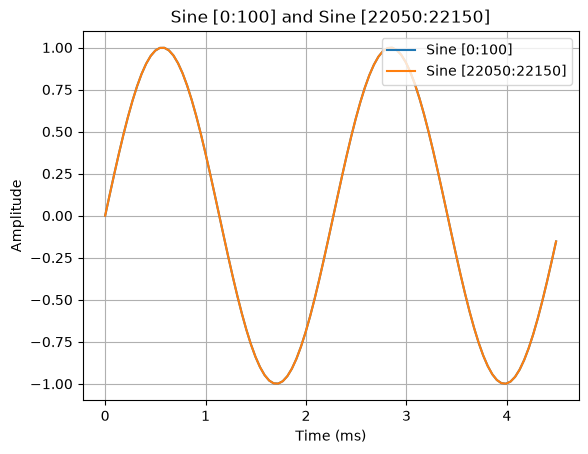

Sine [0:100] and Sine [22050:22150]
-----------------------------------
Results of np.all(a==b) : False
Results of np.allclose(a, b) : True
Rsults of np.max(np.abs(a - b)) : 4.711231404996852e-13


In [6]:
# เปรียบเทียบคู่ที่ 2

# สร้างช่วงระยะเวลาสำหรับการแสดงสัญญาณ 2 วินาที
t_2 = np.arange(0, 2, 1/sr)

x_2 = 2 * np.pi * frequency * t_2   

a_2 = np.sin(x_2)   # สร้างสัญญาณ Sine ระยะเวลา 2 วินาที
Sine_1st_interval = a_2[0:100]
Sine_2nd_interval = a_2[22050:22150]

# -- Plot Graph --
fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine [0:100] and Sine [22050:22150]")
ax.grid()

ax.plot(t_2[0:100]*1000, Sine_1st_interval, label="Sine [0:100]")
ax.plot(t_2[0:100]*1000, Sine_2nd_interval, label="Sine [22050:22150]")
ax.legend(loc="upper right")
plt.show()

# -- เปรียบเทียบระหว่าง Sine [0:100] และ Sine [22050:22150] --
print("Sine [0:100] and Sine [22050:22150]")
print("-----------------------------------")
print(f'Results of np.all(a==b) : {np.all(Sine_1st_interval == Sine_2nd_interval)}')    # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัว ถ้ามีตัวใดตัวหนึ่ง False ก็จะ False เลย
print(f'Results of np.allclose(a, b) : {np.allclose(Sine_1st_interval,Sine_2nd_interval)}') # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัวเหมือนกัน แต่ว่าขอแค่ใกล้เคียงมากพอประมาณ atol + rtol × |b|
print(f'Rsults of np.max(np.abs(a - b)) : {np.max(np.abs(Sine_1st_interval - Sine_2nd_interval))}') # เปรียบเทียบจุดแต่ละจุดของกราฟนำมาลบกันและผ่านค่าสัมบูรณ์แล้วเลือกจุดที่แตกต่างกันมากที่สุด


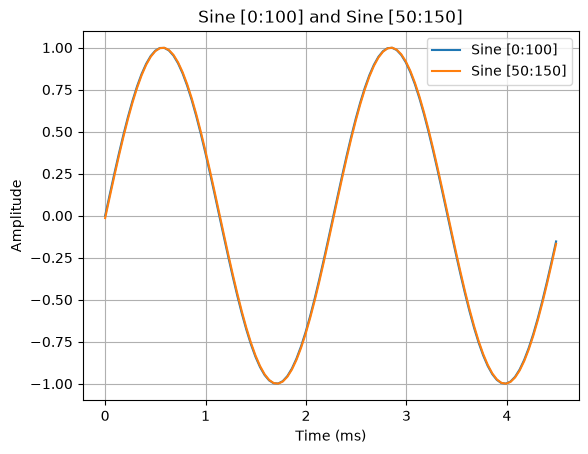

Sine [0:100] and Sine [50:150]
-----------------------------
Results of np.all(a==b) : False
Results of np.allclose(a, b) : False
Rsults of np.max(np.abs(a - b)) : 0.014247103707102927


In [7]:
# เปรียบเทียบคู่ที่ 3 

Sine_1_period = a_2[50:150]

# -- Plot Graph --
fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine [0:100] and Sine [50:150]")
ax.grid()

ax.plot(t_2[0:100]*1000, Sine_1st_interval, label="Sine [0:100]")
ax.plot(t_2[0:100]*1000, Sine_1_period, label="Sine [50:150]")
ax.legend(loc="upper right")
plt.show()

# -- เปรียบเทียบระหว่าง Sine [0:100] และ Sine [50:150] --
print("Sine [0:100] and Sine [50:150]")
print("-----------------------------")
print(f'Results of np.all(a==b) : {np.all(Sine_1st_interval == Sine_1_period)}')    # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัว ถ้ามีตัวใดตัวหนึ่ง False ก็จะ False เลย
print(f'Results of np.allclose(a, b) : {np.allclose(Sine_1st_interval,Sine_1_period)}') # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัวเหมือนกัน แต่ว่าขอแค่ใกล้เคียงมากพอประมาณ atol + rtol × |b| 
print(f'Rsults of np.max(np.abs(a - b)) : {np.max(np.abs(Sine_1st_interval - Sine_1_period))}') # เปรียบเทียบจุดแต่ละจุดของกราฟนำมาลบกันและผ่านค่าสัมบูรณ์แล้วเลือกจุดที่แตกต่างกันมากที่สุด